## Customer Segmentation using KMeans (using Pipeline format):

**NOTE:** In this project, the optimal number of clusters was already determined in the previous notebook, which did not include the pipeline implementation.

### _- A Project by Om Satyawan Pathak_

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

In [2]:

#1. Load the dataset:
df = pd.read_csv("Mall_Customers.csv")
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:


#2. Feature Selection and Transformation:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

#3. Building the customer-classification pipeline:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10))
])
pipeline.fit(X)

df['Cluster'] = pipeline.predict(X)



#4. For checking the correct number of clusters based on silhoutte score:
sil = silhouette_score(
    pipeline.named_steps['scaler'].transform(X),
    df['Cluster']
)
print(f"Silhouette Score: {sil:.5f}")


Silhouette Score: 0.55466


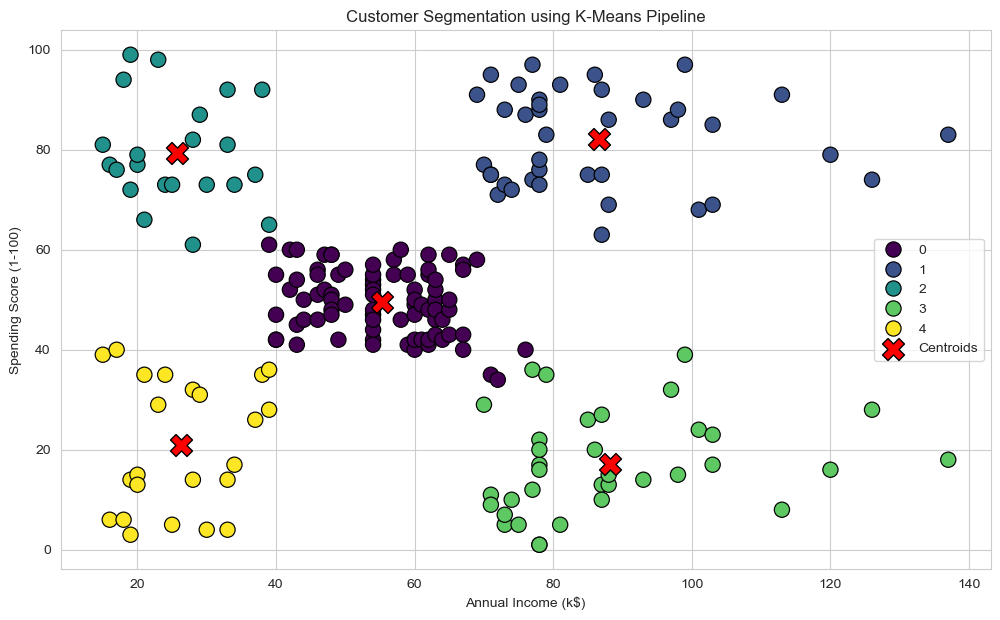

In [4]:


#5. Visualize the clusters:
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)', y='Spending Score (1-100)',
    hue='Cluster', palette='viridis', edgecolor='black', s=120
)

centers_scaled = pipeline.named_steps['kmeans'].cluster_centers_
centers = pipeline.named_steps['scaler'].inverse_transform(centers_scaled)

plt.scatter(
    centers[:, 0], centers[:, 1],
    s=250, marker='X', c='red', label='Centroids', edgecolor='black'
)
plt.title('Customer Segmentation using K-Means Pipeline')
plt.legend()
plt.show()




In [5]:


#6. Displaying the clusters summary:
cluster_summary = df.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending=('Spending Score (1-100)', 'mean')
).round()

cluster_summary



,Customers,Average_Age,Average_Income,Average_Spending
Cluster,,,,
0,81,43.0,55.0,50.0
1,39,33.0,87.0,82.0
2,22,25.0,26.0,79.0
3,35,41.0,88.0,17.0
4,23,45.0,26.0,21.0


In [6]:

#7. Exporting the pipeline for production use:
joblib.dump(pipeline, "complete_customer_segmentation_pipeline.pkl")
print("Pipeline saved to complete_customer_segmentation_pipeline.pkl")



#8. Classifying new customer-data using the pipeline:
def classify_customer(income, spending_score, model=pipeline):
    new_data = np.array([[income, spending_score]])
    return int(model.predict(new_data)[0])
new_customer = {"income": 200, "spending_score": 75}
label = classify_customer(**new_customer)

if label==0:
    print(f"New Customer {new_customer}  | Moderate-Income, Moderate-Spending Customers")
elif label==1:
    print(f"New Customer {new_customer}  | High-Income, High-Spending Customers")
elif label==2:
    print(f"New Customer {new_customer}  | Low-Income, High-Spending Customers")
elif label==3:
    print(f"New Customer {new_customer}  | High-Income, Low-Spending Customers")
else:
    print(f"New Customer {new_customer}  | Low-Income, Low-Spending Customers")

Pipeline saved to complete_customer_segmentation_pipeline.pkl
New Customer {'income': 200, 'spending_score': 75}  | High-Income, High-Spending Customers
